In [1]:
import pandas as pd
import numpy as np
import random

# Pour le GNN
import torch
import torch.nn as nn
import torch.optim as optim
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv
from torch_geometric.utils import negative_sampling
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import  StandardScaler

# Pour faire un "value counts"
from collections import Counter

# Convertir des str en dict même si eval le fait déjà
import ast 
# Retirer les warnings
import warnings
warnings.filterwarnings('ignore')


c:\Users\User\miniconda3\envs\Lab\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# df_users = pd.read_parquet("user1.parquet")
# df_rest = pd.read_json("business1.json")
# df_review = pd.read_parquet("review1.parquet")

In [3]:
# df_rest_b = df_rest.drop(columns=['name', 'address', 'city', 'state', 'postal_code',
#        'latitude', 'longitude', 'is_open', 'HairSpecializesIn', 'AcceptsInsurance'])



In [4]:
# df_users_b = df_users.drop(columns=['compliment_hot',
#        'compliment_more', 'compliment_profile', 'compliment_cute',
#        'compliment_list', 'compliment_note', 'compliment_plain',
#        'compliment_cool', 'compliment_funny', 'compliment_writer',
#        'compliment_photos', 'friends', 'name', 'fans', 'useful', 'funny',
#        'cool', 'elite'])

In [5]:
# df_review_b = df_review.drop(columns=['useful', 'funny',
#        'cool', 'date', 'text'])



---

In [6]:
# E1:

# Charger les datasets
users_df = pd.read_parquet('user1.parquet')
reviews_df = pd.read_parquet('review1.parquet')
restaurants_df = pd.read_json("business1.json")

reviews_df = reviews_df.drop(columns=['useful', 'funny',
       'cool', 'date', 'text'])

restaurants_df = restaurants_df.drop(columns=['name', 'address', 'city', 'state', 'postal_code',
       'latitude', 'longitude', 'is_open', 'HairSpecializesIn', 'AcceptsInsurance'])

users_df = users_df.drop(columns=['compliment_hot',
       'compliment_more', 'compliment_profile', 'compliment_cute',
       'compliment_list', 'compliment_note', 'compliment_plain',
       'compliment_cool', 'compliment_funny', 'compliment_writer',
       'compliment_photos', 'friends', 'name', 'fans', 'useful', 'funny',
       'cool', 'elite', 'yelping_since'])

# E2: Subset

# Sélectionner les users les plus actifs
top_users = users_df.nlargest(10000, 'review_count')['user_id'].values

# Filtrer les reviews de ces users
subset_reviews = reviews_df[reviews_df['user_id'].isin(top_users)].copy()

# Sélectionner les restaurants les plus reviewés parmi ces reviews
top_restaurants = subset_reviews['business_id'].value_counts().head(5000).index.values

# Filtrer les reviews pour ne garder que ces restaurants
subset_reviews = subset_reviews[subset_reviews['business_id'].isin(top_restaurants)].copy()

# Filtrer les dataframes
subset_users = users_df[users_df['user_id'].isin(subset_reviews['user_id'].unique())].copy()
subset_restaurants = restaurants_df[restaurants_df['business_id'].isin(top_restaurants)].copy()

# E3:preprocessing

subset_users['review_count_log'] = np.log1p(subset_users['review_count'])
subset_users['average_stars_norm'] = subset_users['average_stars'] / 5.0

user_features_cols = ['review_count_log', 'average_stars_norm']


col_to_dict = ["BusinessParking", "Ambience", "GoodForMeal"]
for col in col_to_dict:
    subset_restaurants[col] = subset_restaurants[col].apply(lambda x: ast.literal_eval(x))

# Features numériques de base
subset_restaurants['stars_norm'] = subset_restaurants['stars'] / 5.0
subset_restaurants['review_count_log'] = np.log1p(subset_restaurants['review_count'])

# Price Range
subset_restaurants['RestaurantsPriceRange2'] = pd.to_numeric(subset_restaurants['RestaurantsPriceRange2'], errors='coerce').fillna(2.0) 
subset_restaurants['price_norm'] = subset_restaurants['RestaurantsPriceRange2'] / 4.0


def top_k_categories(k: int):
    # Top k catégories
    all_categories = []
    for cats in subset_restaurants['categories'].dropna():
        if isinstance(cats, str):
            all_categories.extend([c.strip() for c in cats.split(',')])
    cats = [cat for cat, _ in Counter(all_categories).most_common(k)]
    return cats 

top_k_categories = top_k_categories(50)
rmv_list = ['Food', 'Event Planning & Services', 'Venues & Event Spaces', 'Restaurants']

top_k_categories = [i for i in top_k_categories if i not in rmv_list]

for cat in top_k_categories:
    subset_restaurants[f'cat_{cat}'] = subset_restaurants['categories'].apply(lambda x: 1.0 if isinstance(x, str) and cat in x else 0.0)

# Attributs booléens
boolean_attrs = [
    'RestaurantsDelivery', 'OutdoorSeating', 'BusinessAcceptsCreditCards',
    'BikeParking', 'RestaurantsTakeOut', 'GoodForKids', 'Caters',
    'RestaurantsReservations', 'RestaurantsTableService', 'RestaurantsGoodForGroups',
    'WheelchairAccessible', 'HasTV', 'HappyHour', 'DriveThru',
    'BusinessAcceptsBitcoin', 'DogsAllowed', 'Open24Hours'
]

def parse_boolean(val):
    if pd.isna(val) or val is None or val == 'None':
        return 0.0
    if isinstance(val, bool):
        return 1.0 if val else 0.0
    if isinstance(val, str):
        val_lower = val.lower()
        if val_lower in ['true', '1', 'yes']:
            return 1.0
        elif val_lower in ['false', '0', 'no']:
            return 0.0
    return 0.0

for attr in boolean_attrs:
    if attr in subset_restaurants.columns:
        subset_restaurants[f'{attr}_bool'] = subset_restaurants[attr].apply(parse_boolean)

# Attributs catégoriels
categorical_attrs = {
    'WiFi': ['free', 'no', 'paid'],
    'Alcohol': ['full_bar', 'beer_and_wine', 'none'],
    'NoiseLevel': ['quiet', 'average', 'loud', 'very_loud'],
    'RestaurantsAttire': ['casual', 'dressy', 'formal'],
    'Smoking': ['no', 'yes', 'outdoor'],
    "BusinessParking": ['garage', 'lot', 'street', 'valet', 'validated'],
    "Ambience": ['casual', 'classy', 'divey', 'hipster', 'intimate', 'romantic', 'touristy', 'trendy','upscale'],
    "GoodForMeal": ['lunch', 'brunch', 'dessert', 'dinner', 'latenight', 'breakfast']
}

for attr, values in categorical_attrs.items():
    if attr in subset_restaurants.columns:
        for val in values:
            subset_restaurants[f'{attr}_{val}'] = subset_restaurants[attr].apply(lambda x: 1.0 if isinstance(x, str) and val in x.lower() and x!="None" else 0.0)

# Compiler toutes les features restaurants
restaurant_features_cols = (
    ['stars_norm', 'review_count_log', 'price_norm'] +
    [f'cat_{cat}' for cat in top_k_categories] +
    [f'{attr}_bool' for attr in boolean_attrs if attr in subset_restaurants.columns] +
    [f'{attr}_{val}' for attr, values in categorical_attrs.items() 
     for val in values if attr in subset_restaurants.columns]
)

subset_restaurants_fillna = subset_restaurants[restaurant_features_cols].fillna(0)
subset_users_fillna = subset_users[user_features_cols].fillna(0)

In [7]:
# # E4: Création du Graphe

# # Créer les mappings
# user_to_idx = {uid: i for i, uid in enumerate(subset_users['user_id'])}
# num_users = len(user_to_idx)
# restaurant_to_idx = {rid: i+ num_users for i, rid in enumerate(subset_restaurants['business_id'])}
# restaurant_idx_id = {i+ num_users: rid  for i, rid in enumerate(subset_restaurants['business_id'])}


# num_restaurants = len(restaurant_to_idx)


# # Normaliser les features
# scaler_user = StandardScaler()
# scaler_restaurant = StandardScaler()

# user_features = scaler_user.fit_transform(subset_users_fillna)
# restaurant_features = scaler_restaurant.fit_transform(subset_restaurants_fillna)

# # Padding pour avoir la même dimension
# max_dim = max(user_features.shape[1], restaurant_features.shape[1])

# user_features_padded = np.pad(
#     user_features,
#     ((0, 0), (0, max_dim - user_features.shape[1])),
#     mode='constant'
# )
# restaurant_features_padded = np.pad(
#     restaurant_features,
#     ((0, 0), (0, max_dim - restaurant_features.shape[1])),
#     mode='constant'
# )

# # Combiner
# all_features = np.vstack([user_features_padded, restaurant_features_padded])
# x = torch.FloatTensor(all_features)

# edge_list = []
# edge_labels = []

# # Likes 
# likes = subset_reviews[subset_reviews['stars'] >= 3]
# for _, row in likes.iterrows():
#     if row['user_id'] in user_to_idx and row['business_id'] in restaurant_to_idx:
#         user_idx = user_to_idx[row['user_id']]
#         restaurant_idx = restaurant_to_idx[row['business_id']]
        
#         edge_list.append([user_idx, restaurant_idx])
#         edge_list.append([restaurant_idx, user_idx])
#         edge_labels.extend([1.0, 1.0])

# # Dislikes
# dislikes = subset_reviews[subset_reviews['stars'] <= 2]
# for _, row in dislikes.iterrows():
#     if row['user_id'] in user_to_idx and row['business_id'] in restaurant_to_idx:
#         user_idx = user_to_idx[row['user_id']]
#         restaurant_idx = restaurant_to_idx[row['business_id']]
        
#         edge_list.append([user_idx, restaurant_idx])
#         edge_list.append([restaurant_idx, user_idx])
#         edge_labels.extend([0.0, 0.0])

# edge_index = torch.LongTensor(edge_list).t().contiguous()
# edge_label = torch.FloatTensor(edge_labels)

# print(f"Edges: {edge_index.shape[1]:,}")
# print(f"Likes: {(edge_label == 1.0).sum().item():,}")
# print(f"Dislikes: {(edge_label == 0.0).sum().item():,}")

# graph_data = Data(x=x, edge_index=edge_index, edge_label=edge_label)


In [8]:
# # E5: GNN

# class RestaurantGNN(nn.Module):
#     def __init__(self, in_channels, hidden_channels, out_channels):
#         super().__init__()
#         self.conv1 = SAGEConv(in_channels, hidden_channels)
#         self.conv2 = SAGEConv(hidden_channels, out_channels)
#         self.predictor = nn.Sequential(
#             nn.Linear(out_channels * 2, hidden_channels),
#             nn.ReLU(),
#             nn.Dropout(0.3),
#             nn.Linear(hidden_channels, hidden_channels // 2),
#             nn.ReLU(),
#             nn.Linear(hidden_channels // 2, 1)
#         )
        
#     def encode(self, x, edge_index):
#         x = self.conv1(x, edge_index).relu()
#         x = self.conv2(x, edge_index)
#         return x
    
#     def decode(self, z, edge_label_index):
#         src = z[edge_label_index[0]]
#         dst = z[edge_label_index[1]]
#         return self.predictor(torch.cat([src, dst], dim=1)).squeeze()
    
#     def forward(self, x, edge_index, edge_label_index):
#         z = self.encode(x, edge_index)
#         return self.decode(z, edge_label_index)

# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# model = RestaurantGNN(
#     in_channels=max_dim,
#     hidden_channels=128,
#     out_channels=64
# ).to(device)



In [9]:
# optimizer = optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
# criterion = nn.BCEWithLogitsLoss()

# data = graph_data.to(device)

# num_epochs = 50

# model.train()
# for epoch in range(num_epochs):
#     optimizer.zero_grad()
    
#     # Negative sampling
#     neg_edge_index = negative_sampling(
#         edge_index=data.edge_index,
#         num_nodes=data.num_nodes,
#         num_neg_samples=data.edge_index.size(1) // 2
#     )
    
#     # Combiner edges positifs et négatifs
#     edge_label_index = torch.cat([data.edge_index, neg_edge_index], dim=1)
#     edge_label = torch.cat([
#         data.edge_label,
#         torch.zeros(neg_edge_index.size(1))
#     ], dim=0).to(device)
    
#     # Forward pass
#     out = model(data.x, data.edge_index, edge_label_index)
#     loss = criterion(out, edge_label)
    
#     # Backward pass
#     loss.backward()
#     optimizer.step()
    
#     # Metrics
#     if epoch % 5 == 0:
#         with torch.no_grad():
#             pred = out.cpu().numpy()
#             true = edge_label.cpu().numpy()
#             auc = roc_auc_score(true, pred) if len(np.unique(true)) > 1 else 0.5
#             acc = ((pred > 0.5) == true).mean()
            
#             print(f"Epoch {epoch:03d} | Loss: {loss:.4f} | AUC: {auc:.4f} | Acc: {acc:.4f}")

In [10]:

# def get_top_k_recommendations(user_id, k=20, verbose=True):
#     """
#     Obtient les top K recommandations pour un user
    
#     Args:
#         user_id: ID du user
#         k: Nombre de recommandations
#         verbose: Afficher les détails
    
#     Returns:
#         List of (restaurant_id, score, restaurant_info)
#     """
#     if user_id not in user_to_idx:
#         print(f"User {user_id} non trouvé dans le subset")
#         return []
    
#     model.eval()
#     with torch.no_grad():
#         # Encoder le graphe
#         z = model.encode(data.x, data.edge_index)
        
#         user_idx = user_to_idx[user_id]
        
#         # Calculer les scores pour tous les restaurants
#         scores = [] 
#         for restaurant_id, restaurant_idx in restaurant_to_idx.items():
            
#             edge_label_index = torch.tensor(
#                 [[user_idx], [restaurant_idx]], 
#                 device=device
#             )
#             score = model.decode(z, edge_label_index)
#             probs = torch.sigmoid(score)
#             scores.append((restaurant_id, probs))
        
#         # Trier par score décroissant
#         scores.sort(key=lambda x: x[1], reverse=True)
#         top_k = scores[:k]
        
#         # Enrichir avec les infos restaurants
#         recommendations = []
#         for restaurant_id, score in top_k:
#             restaurant_info = subset_restaurants[subset_restaurants['business_id'] == restaurant_id].iloc[0].to_dict()
#             recommendations.append((restaurant_id, score, restaurant_info))
        
#         if verbose:
#             print(f"Top {k} recommandations pour user {user_id}:")
#             for i, (_, score, info) in enumerate(recommendations, 1):
#                 print(f"{i}. Score: {score:.4f} | Stars: {info['stars']:.1f} | {info}")
        
#         return recommendations
    


# # E7: recommandation

# # Test avec un user aléatoire
# test_user = subset_users.iloc[0]['user_id']
# recs = get_top_k_recommendations(test_user, k=20)


---

In [11]:
# def add_edge(user_id, rest_id_list, preference_list):
#     edge = graph_data.edge_index.T.tolist()
#     label = graph_data.edge_label.cpu().tolist()
    
#     exist_edges = list(map(lambda x: (restaurant_idx_id[x[0]], x[1]), [(elt[1],l) for elt, l in zip(edge, label) if elt[0] == user_to_idx[user_id]]))
#     exist_res = [r[0] for r in exist_edges]
#     exist_label = [r[1] for r in exist_edges]

#     if user_id not in user_to_idx:
#         print("user is not in user_to_idx")
#         return False
    
#     if not (rest_id_list and all([True if rest in restaurant_to_idx else False for rest in rest_id_list])):
#         print("restaurant not in restaurant_to_idx")
#         return False
    
#     if set(preference_list) not in [{1, 0}, {1}, {0}]:
#         return False
    
#     if len(preference_list) != len(rest_id_list):
#         return False
  
#     rmv = []
#     # Change like to dislike
#     for i, (res, pref) in enumerate(zip(rest_id_list, preference_list)):
#         if res in exist_res:
#             if pref == exist_label[exist_res.index(res)]:
#                 return False
#             else:
#                 index = graph_data.edge_index.T.cpu().tolist().index([user_to_idx[user_id], restaurant_to_idx[res]])
#                 if pref == 0:
#                     graph_data.edge_label[index] = 1
#                 else: 
#                     graph_data.edge_label[index] = 0
#                 rmv.append(i)

    
#     rest_id_list = [rest_id_list[i] for i in range(len(rest_id_list)) if i not in rmv]
#     preference_list = [preference_list[i] for i in range(len(preference_list)) if i not in rmv]

    
#     edge_list = []
#     edge_labels = []

#     user_idx = user_to_idx[user_id]
#     for rest, pref in zip(rest_id_list, preference_list):
#         restaurant_idx = restaurant_to_idx[rest]
#         edge_list.append([user_idx, restaurant_idx])
#         edge_list.append([restaurant_idx, user_idx])

#         if pref == 1:
#             edge_labels.extend([1.0, 1.0])
#         else:
#             edge_labels.extend([0.0, 0.0])

#     new_edge_index = torch.LongTensor(edge_list).t().contiguous()
#     new_edge_label = torch.FloatTensor(edge_labels)
    
#     graph_data.edge_index = torch.cat([graph_data.edge_index, new_edge_index], dim=1)
#     graph_data.edge_label = torch.cat([graph_data.edge_label, new_edge_label])
    
#     return True


In [12]:
# Ceci est un TEST pour modifier le label d'une arête

# user_id = 'si99SgWBLfk0WX3dZJhWlA'
# rest_id = '9OG5YkX1g2GReZM0AskizA'
# index = graph_data.edge_index.T.cpu().tolist().index([user_to_idx[user_id], restaurant_to_idx[rest_id]])
# graph_data.edge_label[index] = 1


In [13]:
# Ceci est un TEST pour tester la fonction add_edge

# add_edge(user_id="R[x{=dx1dOy<{OFaRG4EAh", rest_id_list=["9OG5YkX1g2GReZM0AskizA", "YNjyv0gfOr2g8lbmUpTnKg"], preference_list=[1, 0])

In [14]:
# # Ceci est un TEST pour permettre de voir les relations existantes pour un restaurant donné

# edge = graph_data.edge_index.T.cpu().tolist()
# edges = []
# for elt in edge:
#     if elt[0] == 14893:
#         edges.append(elt)
# print(edges)

In [15]:
# lst = [14323, 10618]
# for i in lst:
#     display(subset_restaurants[subset_restaurants["business_id"] == restaurant_idx_id[i]])
#     print()

In [16]:
# Ceci est un TEST pour voir les restaurants likés ou dislikés par un user

# subset_reviews[subset_reviews["user_id"] == "si99SgWBLfk0WX3dZJhWlA"].review_id.tolist()

In [17]:
# def get_propositions(idx):

#     for i in idx:
#         if len(i) != 0:
#             print(subset_restaurants[subset_restaurants.index.isin(i) & (subset_restaurants["stars"]>=3)].sort_values(by = "stars", ascending=False).sample(5 if len(i)>=5 else len(i)))


# def select_categories(user_id):
#     print("What type of food do you prefer ?")
#     cat = top_k_categories(30)
#     print(cat)
#     # provisoire car on n'a pas d'interface encore 
#     # Pas de blindage ici
#     ipt = str(input("Input: ")).split()
#     idx = []
#     for i in ipt:
#         idx.append(subset_restaurants[subset_restaurants["categories"].str.contains(i)].index.tolist())
    
#     get_propositions(idx)

#     print("\n# Like/ Dislike:")
#     ipt_rest = str(input("Restaurant ID's:")).split()
#     ipt_labels = list(map(int, str(input("Lables:")).split()))
#     return add_edge(user_id, ipt_rest, ipt_labels)


    


In [18]:
# def generate_user_id():
#     user_id = "".join([chr(random.randint(48, 125)) for _ in range(22)])
#     if user_id in user_to_idx:
#         generate_user_id()
#     else:
#         return user_id
    

# def add_user():
#     new_user_features_raw = np.array([[0, 0.7]])

#     # Normalisation
#     new_user_features = scaler_user.transform(new_user_features_raw)

#     new_user_features_padded = np.pad(
#         new_user_features,
#         ((0, 0), (0, max_dim - new_user_features.shape[1])),
#         mode='constant'
#     )

#     user_id = generate_user_id()
#     user_to_idx[user_id] = len(restaurant_to_idx)+len(user_to_idx)

#     graph_data.x = torch.cat([
#             graph_data.x,
#             torch.FloatTensor(new_user_features_padded)
#         ], dim=0)
    
#     return user_id

In [19]:
# def cold_start():
#     u_id = add_user()
#     val = select_categories(u_id)
#     if val:
#         print("Success !")
#     else:
#         print("Error...")
    
#     return u_id 

# id = cold_start()

# recs = get_top_k_recommendations(id, k=10)
    

In [20]:
# recs = get_top_k_recommendations("8z[hqz1C4{hMW\=>50qrx4", k=20)


---


In [21]:
# E1: Création du graph 1 pour le link predictor

import torch
from torch_geometric.data import Data
from sklearn.preprocessing import StandardScaler
import numpy as np

user_to_idx = {uid: i for i, uid in enumerate(subset_users['user_id'])}
num_users = len(user_to_idx)

restaurant_to_idx = {rid: i + num_users for i, rid in enumerate(subset_restaurants['business_id'])}
restaurant_idx_id = {i + num_users: rid for i, rid in enumerate(subset_restaurants['business_id'])}

num_restaurants = len(restaurant_to_idx)


scaler_user = StandardScaler()
scaler_restaurant = StandardScaler()

user_features = scaler_user.fit_transform(subset_users_fillna)
restaurant_features = scaler_restaurant.fit_transform(subset_restaurants_fillna)


max_dim = max(user_features.shape[1], restaurant_features.shape[1])

user_features_padded = np.pad(
    user_features,
    ((0, 0), (0, max_dim - user_features.shape[1])),
    mode='constant'
)
restaurant_features_padded = np.pad(
    restaurant_features,
    ((0, 0), (0, max_dim - restaurant_features.shape[1])),
    mode='constant'
)


all_features = np.vstack([user_features_padded, restaurant_features_padded])
x = torch.FloatTensor(all_features)


# Ici, on prend toutes les interactions existantes, sans se préoccuper du like/dislike
edge_list = []

interactions = subset_reviews[
    subset_reviews['user_id'].isin(user_to_idx) & 
    subset_reviews['business_id'].isin(restaurant_to_idx)
]

for _, row in interactions.iterrows():
    user_idx = user_to_idx[row['user_id']]
    restaurant_idx = restaurant_to_idx[row['business_id']]
    
    # On ajoute une arête bidirectionnelle
    edge_list.append([user_idx, restaurant_idx])
    edge_list.append([restaurant_idx, user_idx])

edge_index = torch.LongTensor(edge_list).t().contiguous()


graph_data = Data(x=x, edge_index=edge_index)

print(f"Number of nodes: {graph_data.num_nodes}")
print(f"Number of edges: {graph_data.num_edges}")


Number of nodes: 14892
Number of edges: 337124


In [38]:
# E2: GNN 1: LinkPredictor

import torch
import torch.nn as nn
from torch_geometric.nn import SAGEConv
from torch_geometric.utils import negative_sampling
from torch_geometric.transforms import RandomLinkSplit
from torch_geometric.data import Data


class GNNLinkPredictor(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.in_channels = in_channels
        self.hidden_channels = hidden_channels
        self.out_channels = out_channels
        self.conv1 = SAGEConv(in_channels, hidden_channels)
        self.conv2 = SAGEConv(hidden_channels, out_channels)
        self.relu = nn.ReLU()

    def encode(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = self.relu(x)
        x = self.conv2(x, edge_index)
        return x

    def decode(self, z, edge_label_index):
        # Produit scalaire entre embeddings source et destination
        src = z[edge_label_index[0]]
        dst = z[edge_label_index[1]]
        return (src * dst).sum(dim=1)

    def forward(self, x, edge_index, edge_label_index):
        z = self.encode(x, edge_index)
        return self.decode(z, edge_label_index)
    
    def save(self, filepath):
        torch.save({
            "state_dict": self.state_dict(),
            "in_channels": self.in_channels,
            "hidden_channels": self.hidden_channels,
            "out_channels": self.out_channels
        }, filepath)
        
    @classmethod
    def load(cls, filepath, device="cpu"):
        checkpoint = torch.load(filepath, map_location=device)

        model = cls(
            checkpoint["in_channels"],
            checkpoint["hidden_channels"],
            checkpoint["out_channels"]
        )
        model.load_state_dict(checkpoint["state_dict"])
        model.to(device)
        model.eval()

        return model

transform = RandomLinkSplit(
    num_val=0.1,
    num_test=0.1,
    is_undirected=True,
    add_negative_train_samples=True  # Génère des arêtes négatives pour l'entraînement
)

train_data, val_data, test_data = transform(graph_data)


Epoch 000 | Train Loss: 0.9705 | Val Loss: 0.8077 | AUC Train: 0.3176 | AUC Val: 0.3114
Epoch 005 | Train Loss: 0.7221 | Val Loss: 0.7103 | AUC Train: 0.4761 | AUC Val: 0.5055
Epoch 010 | Train Loss: 0.6828 | Val Loss: 0.6848 | AUC Train: 0.6936 | AUC Val: 0.6723
Epoch 015 | Train Loss: 0.6603 | Val Loss: 0.6621 | AUC Train: 0.7655 | AUC Val: 0.7407
Epoch 020 | Train Loss: 0.6308 | Val Loss: 0.6377 | AUC Train: 0.7782 | AUC Val: 0.7511
Epoch 025 | Train Loss: 0.6054 | Val Loss: 0.6189 | AUC Train: 0.7950 | AUC Val: 0.7674
Epoch 030 | Train Loss: 0.5869 | Val Loss: 0.6057 | AUC Train: 0.8173 | AUC Val: 0.7859
Epoch 035 | Train Loss: 0.5715 | Val Loss: 0.5949 | AUC Train: 0.8412 | AUC Val: 0.8048


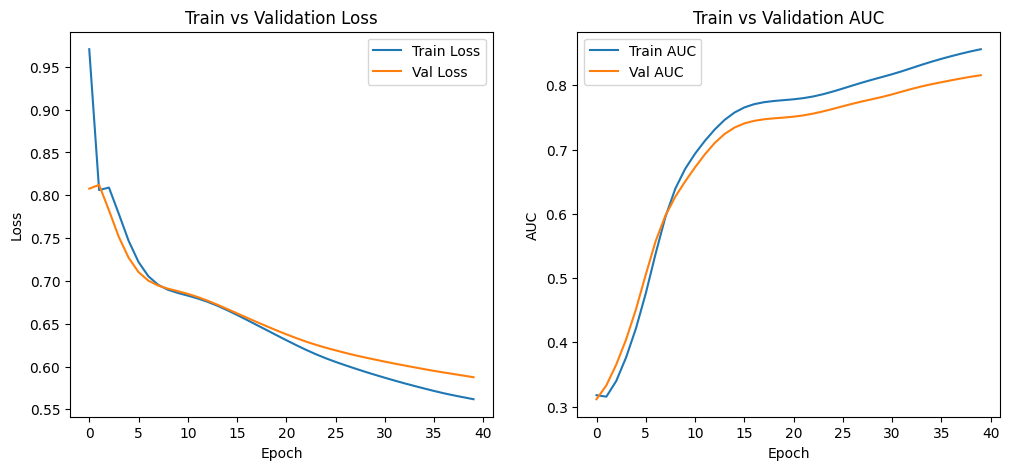

In [39]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model_linkpred = GNNLinkPredictor(
    in_channels=graph_data.num_node_features,
    hidden_channels=128,
    out_channels=64
).to(device)

optimizer = torch.optim.Adam(model_linkpred.parameters(), lr=0.005, weight_decay=5e-3)
criterion = nn.BCEWithLogitsLoss()


num_epochs = 40

# Stockage des metrics
train_losses, val_losses = [], []
train_aucs, val_aucs = [], []

for epoch in range(num_epochs):
    model_linkpred.train()
    optimizer.zero_grad()

    edge_label_index = train_data.edge_label_index.to(device)
    edge_label = train_data.edge_label.to(device)

    out = model_linkpred(train_data.x.to(device), train_data.edge_index.to(device), edge_label_index)
    loss = criterion(out, edge_label)
    loss.backward()
    optimizer.step()

    # Stocker metrics train
    train_losses.append(loss.item())
    pred_prob = torch.sigmoid(out).cpu().detach().numpy()
    train_aucs.append(roc_auc_score(edge_label.cpu(), pred_prob))

    # Validation
    model_linkpred.eval()
    with torch.no_grad():
        val_edge_index = val_data.edge_label_index.to(device)
        val_edge_label = val_data.edge_label.to(device)

        val_out = model_linkpred(val_data.x.to(device), val_data.edge_index.to(device), val_edge_index)
        val_loss = criterion(val_out, val_edge_label)
        val_losses.append(val_loss.item())

        val_pred_prob = torch.sigmoid(val_out).cpu().numpy()
        val_aucs.append(roc_auc_score(val_edge_label.cpu(), val_pred_prob))

    if epoch % 5 == 0:
        print(f"Epoch {epoch:03d} | Train Loss: {loss:.4f} | Val Loss: {val_loss:.4f} | "
              f"AUC Train: {train_aucs[-1]:.4f} | AUC Val: {val_aucs[-1]:.4f}")



import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train vs Validation Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(train_aucs, label='Train AUC')
plt.plot(val_aucs, label='Val AUC')
plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.title("Train vs Validation AUC")
plt.legend()

plt.show()


In [25]:
# E5: Création du Graphe 2 pour GNNEdgeLabelPredictor

import torch
from torch_geometric.data import Data
from sklearn.preprocessing import StandardScaler
import numpy as np

user_to_idx = {uid: i for i, uid in enumerate(subset_users['user_id'])}
num_users = len(user_to_idx)

restaurant_to_idx = {rid: i + num_users for i, rid in enumerate(subset_restaurants['business_id'])}
restaurant_idx_id = {i + num_users: rid for i, rid in enumerate(subset_restaurants['business_id'])}

num_restaurants = len(restaurant_to_idx)


scaler_user = StandardScaler()
scaler_restaurant = StandardScaler()

user_features = scaler_user.fit_transform(subset_users_fillna)
restaurant_features = scaler_restaurant.fit_transform(subset_restaurants_fillna)


max_dim = max(user_features.shape[1], restaurant_features.shape[1])

user_features_padded = np.pad(
    user_features,
    ((0, 0), (0, max_dim - user_features.shape[1])),
    mode='constant'
)
restaurant_features_padded = np.pad(
    restaurant_features,
    ((0, 0), (0, max_dim - restaurant_features.shape[1])),
    mode='constant'
)


all_features = np.vstack([user_features_padded, restaurant_features_padded])
x = torch.FloatTensor(all_features)

edge_list = []
edge_labels = []

# Likes
likes = subset_reviews[subset_reviews['stars'] >= 3]
for _, row in likes.iterrows():
    if row['user_id'] in user_to_idx and row['business_id'] in restaurant_to_idx:
        user_idx = user_to_idx[row['user_id']]
        restaurant_idx = restaurant_to_idx[row['business_id']]

        edge_list.append([user_idx, restaurant_idx])
        edge_list.append([restaurant_idx, user_idx])
        edge_labels.extend([1.0, 1.0])

# Dislikes 
dislikes = subset_reviews[subset_reviews['stars'] <= 2]
for _, row in dislikes.iterrows():
    if row['user_id'] in user_to_idx and row['business_id'] in restaurant_to_idx:
        user_idx = user_to_idx[row['user_id']]
        restaurant_idx = restaurant_to_idx[row['business_id']]

        edge_list.append([user_idx, restaurant_idx])
        edge_list.append([restaurant_idx, user_idx])
        edge_labels.extend([0.0, 0.0])

edge_index = torch.LongTensor(edge_list).t().contiguous()
edge_label = torch.FloatTensor(edge_labels)


graph_with_labels = Data(x=x, edge_index=edge_index, edge_label=edge_label)

print(f"Edges: {edge_index.shape[1]:,}")
print(f"Likes: {(edge_label == 1.0).sum().item():,}")
print(f"Dislikes: {(edge_label == 0.0).sum().item():,}")


Edges: 337,124
Likes: 310,604
Dislikes: 26,520


In [42]:
import torch
from torch_geometric.data import Data
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from torch_geometric.nn import SAGEConv

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
class GNNEdgeLabelPredictor(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.in_channels = in_channels
        self.hidden_channels = hidden_channels
        self.out_channels = out_channels
        
        self.conv1 = SAGEConv(in_channels, hidden_channels)
        self.conv2 = SAGEConv(hidden_channels, out_channels)
        self.relu = nn.ReLU()
        self.predictor = nn.Sequential(
            nn.Linear(out_channels*2, hidden_channels),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(hidden_channels, 1)
        )

    def encode(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = self.relu(x)
        x = self.conv2(x, edge_index)
        return x

    def decode(self, z, edge_label_index):
        src = z[edge_label_index[0]]
        dst = z[edge_label_index[1]]
        return self.predictor(torch.cat([src, dst], dim=1)).squeeze()

    def forward(self, x, edge_index, edge_label_index):
        z = self.encode(x, edge_index)
        return self.decode(z, edge_label_index)
    
    def save(self, filepath):
        torch.save({
            "state_dict": self.state_dict(),
            "in_channels": self.in_channels,
            "hidden_channels": self.hidden_channels,
            "out_channels": self.out_channels
        }, filepath)

    @classmethod
    def load(cls, filepath, device="cpu"):
        checkpoint = torch.load(filepath, map_location=device)

        model = cls(
            checkpoint["in_channels"],
            checkpoint["hidden_channels"],
            checkpoint["out_channels"]
        )
        model.load_state_dict(checkpoint["state_dict"])
        model.to(device)
        model.eval()

        return model
    


In [45]:
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# edges = graph_with_labels.edge_index.t().tolist()
# labels = graph_with_labels.edge_label.tolist()

# # Regrouper les paires
# unique_edges = []
# unique_labels = []
# seen = set()

# for i, (edge, label) in enumerate(zip(edges, labels)):
#     u, v = edge
#     # Normaliser : toujours garder (min, max)
#     edge_normalized = tuple(sorted([u, v]))
    
#     if edge_normalized not in seen:
#         unique_edges.append([u, v])
#         unique_labels.append(label)
#         seen.add(edge_normalized)

# print(f"Edges originaux: {len(edges)}")
# print(f"Edges uniques (après dédoublonnage): {len(unique_edges)}")


# from sklearn.model_selection import train_test_split

# train_edges, test_edges, train_labels, test_labels = train_test_split(
#     unique_edges, 
#     unique_labels, 
#     test_size=0.2, 
#     random_state=42,
#     stratify=unique_labels  # Garder la proportion like/dislike
# )

# train_edges, val_edges, train_labels, val_labels = train_test_split(
#     train_edges, 
#     train_labels, 
#     test_size=0.1, 
#     random_state=42,
#     stratify=train_labels
# )

# print(f"\nTrain: {len(train_edges)} edges")
# print(f"Val: {len(val_edges)} edges")
# print(f"Test: {len(test_edges)} edges")


# def create_bidirectional(edges, labels):
#     """Créer les edges bidirectionnels"""
#     bi_edges = []
#     bi_labels = []
    
#     for edge, label in zip(edges, labels):
#         # Direction originale
#         bi_edges.append(edge)
#         bi_labels.append(label)
        
#         # Direction inverse
#         bi_edges.append([edge[1], edge[0]])
#         bi_labels.append(label)
    
#     return bi_edges, bi_labels

# train_edges_bi, train_labels_bi = create_bidirectional(train_edges, train_labels)
# val_edges_bi, val_labels_bi = create_bidirectional(val_edges, val_labels)
# test_edges_bi, test_labels_bi = create_bidirectional(test_edges, test_labels)

# # Convertir en tensors
# train_edge_index = torch.tensor(train_edges_bi, dtype=torch.long).t()
# train_edge_label = torch.tensor(train_labels_bi, dtype=torch.long)

# val_edge_index = torch.tensor(val_edges_bi, dtype=torch.long).t()
# val_edge_label = torch.tensor(val_labels_bi, dtype=torch.long)

# test_edge_index = torch.tensor(test_edges_bi, dtype=torch.long).t()
# test_edge_label = torch.tensor(test_labels_bi, dtype=torch.long)

# print(f"\nAprès bidirectionnalisation:")
# print(f"Train: {train_edge_index.shape[1]} edges")
# print(f"Val: {val_edge_index.shape[1]} edges")
# print(f"Test: {test_edge_index.shape[1]} edges")

def create_bidirectional(edges, labels):
    bi_edges, bi_labels = [], []
    for edge, label in zip(edges, labels):
        bi_edges.append(edge)
        bi_labels.append(label)
        bi_edges.append([edge[1], edge[0]])
        bi_labels.append(label)
    return bi_edges, bi_labels


def prepare_edge_splits(graph_with_labels, test_size=0.2, val_size=0.1, random_state=42):
    import torch
    from sklearn.model_selection import train_test_split

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    edges = graph_with_labels.edge_index.t().tolist()
    labels = graph_with_labels.edge_label.tolist()

    unique_edges = []
    unique_labels = []
    seen = set()

    for edge, label in zip(edges, labels):
        u, v = edge
        edge_norm = tuple(sorted([u, v]))
        if edge_norm not in seen:
            unique_edges.append([u, v])
            unique_labels.append(label)
            seen.add(edge_norm)

    print(f"Edges originaux: {len(edges)}")
    print(f"Edges uniques (après dédoublonnage): {len(unique_edges)}")

    train_edges, test_edges, train_labels, test_labels = train_split = train_test_split(
        unique_edges,
        unique_labels,
        test_size=test_size,
        random_state=random_state,
        stratify=unique_labels
    )

    train_edges, val_edges, train_labels, val_labels = train_test_split(
        train_edges,
        train_labels,
        test_size=val_size,
        random_state=random_state,
        stratify=train_labels
    )

    print(f"\nTrain: {len(train_edges)} edges")
    print(f"Val:   {len(val_edges)} edges")
    print(f"Test:  {len(test_edges)} edges")

    train_edges_bi, train_labels_bi = create_bidirectional(train_edges, train_labels)
    val_edges_bi, val_labels_bi = create_bidirectional(val_edges, val_labels)
    test_edges_bi, test_labels_bi = create_bidirectional(test_edges, test_labels)

    train_edge_index = torch.tensor(train_edges_bi, dtype=torch.long).t().to(device)
    train_edge_label = torch.tensor(train_labels_bi, dtype=torch.long).to(device)

    val_edge_index = torch.tensor(val_edges_bi, dtype=torch.long).t().to(device)
    val_edge_label = torch.tensor(val_labels_bi, dtype=torch.long).to(device)

    test_edge_index = torch.tensor(test_edges_bi, dtype=torch.long).t().to(device)
    test_edge_label = torch.tensor(test_labels_bi, dtype=torch.long).to(device)

    print(f"\nAprès bidirectionnalisation :")
    print(f"Train: {train_edge_index.shape[1]} edges")
    print(f"Val:   {val_edge_index.shape[1]} edges")
    print(f"Test:  {test_edge_index.shape[1]} edges")

    return (
        train_edge_index, train_edge_label,
        val_edge_index, val_edge_label,
        test_edge_index, test_edge_label
    )



train_edge_index, train_edge_label, val_edge_index, val_edge_label, test_edge_index, test_edge_label = prepare_edge_splits(graph_with_labels)

Edges originaux: 337124
Edges uniques (après dédoublonnage): 156521

Train: 112694 edges
Val:   12522 edges
Test:  31305 edges

Après bidirectionnalisation :
Train: 225388 edges
Val:   25044 edges
Test:  62610 edges


pos_weight = 0.07834956844583087
Edges in train: 225388
Edges in val: 25044
Overlap: 0
Epoch 000 | Train Loss: 0.1008 | Val Loss: 0.1006 | AUC Train: 0.4962 | AUC Val: 0.5443 | Train Acc: 0.4141 | Val Acc: 0.4410
Epoch 001 | Train Loss: 0.1006 | Val Loss: 0.1004 | AUC Train: 0.5264 | AUC Val: 0.5879 | Train Acc: 0.4649 | Val Acc: 0.5185
Epoch 002 | Train Loss: 0.1004 | Val Loss: 0.1002 | AUC Train: 0.5557 | AUC Val: 0.6182 | Train Acc: 0.5055 | Val Acc: 0.5682
Epoch 003 | Train Loss: 0.1002 | Val Loss: 0.1000 | AUC Train: 0.5788 | AUC Val: 0.6376 | Train Acc: 0.5356 | Val Acc: 0.5926
Epoch 004 | Train Loss: 0.1000 | Val Loss: 0.0998 | AUC Train: 0.6003 | AUC Val: 0.6496 | Train Acc: 0.5572 | Val Acc: 0.6046
Epoch 005 | Train Loss: 0.0998 | Val Loss: 0.0996 | AUC Train: 0.6151 | AUC Val: 0.6574 | Train Acc: 0.5714 | Val Acc: 0.6106
Epoch 006 | Train Loss: 0.0995 | Val Loss: 0.0994 | AUC Train: 0.6319 | AUC Val: 0.6625 | Train Acc: 0.5834 | Val Acc: 0.6122
Epoch 007 | Train Loss: 0.0993 

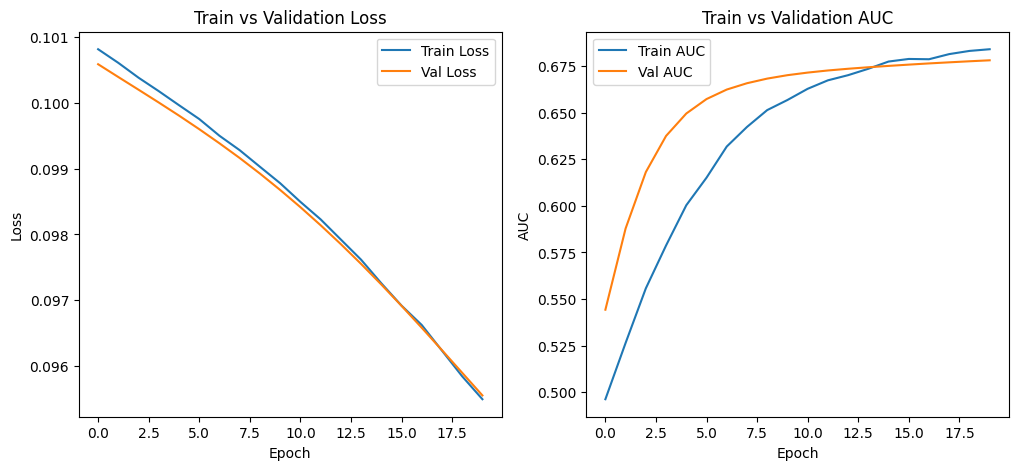

In [ ]:
train_losses, val_losses = [], []
train_aucs, val_aucs = [], []
train_accs, val_accs = [], []

pos = train_edge_label.sum().item()
neg = len(train_edge_label) - pos
pos_weight = neg / pos
print("pos_weight =", pos_weight)

model_labelpred = GNNEdgeLabelPredictor(
    in_channels=graph_with_labels.x.size(1),
    hidden_channels=512,
    out_channels=256
).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], device=device))
optimizer = torch.optim.Adam(model_labelpred.parameters(), lr=0.0001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.0001, patience=5
)

num_epochs = 20

x = graph_with_labels.x.to(device)
# Vérifier qu'il n'y a pas de fuite
train_edges_set = set(map(tuple, train_edge_index.t().tolist()))
val_edges_set = set(map(tuple, val_edge_index.t().tolist()))
overlap = train_edges_set & val_edges_set

print(f"Edges in train: {len(train_edges_set)}")
print(f"Edges in val: {len(val_edges_set)}")
print(f"Overlap: {len(overlap)}") 

if len(overlap) > 0:
    print("ATTENTION: Fuite de données train/val !")
for epoch in range(num_epochs):
    model_labelpred.train()
    optimizer.zero_grad()
    out = model_labelpred(x, graph_with_labels.edge_index.to(device), train_edge_index.to(device))
    loss = criterion(out, train_edge_label.float().to(device))
    loss.backward()
    optimizer.step()

    # Stocker train metrics
    train_losses.append(loss.item())
    train_probs = torch.sigmoid(out).cpu().detach().numpy() 
    train_true = train_edge_label.cpu().numpy()
    train_aucs.append(roc_auc_score(train_true, train_probs))
    train_accs.append(((train_probs > 0.5) == train_true).mean())

    # Validation
    model_labelpred.eval()
    with torch.no_grad():
        val_out = model_labelpred(x, graph_with_labels.edge_index.to(device), val_edge_index.to(device))
        val_loss = criterion(val_out, val_edge_label.float().to(device))
        val_losses.append(val_loss.item())

        val_probs = torch.sigmoid(val_out).cpu().numpy()
        val_true = val_edge_label.cpu().numpy()
        val_aucs.append(roc_auc_score(val_true, val_probs))
        val_accs.append(((val_probs > 0.5) == val_true).mean())

    
        print(f"Epoch {epoch:03d} | Train Loss: {loss:.4f} | Val Loss: {val_loss:.4f} | "
              f"AUC Train: {train_aucs[-1]:.4f} | AUC Val: {val_aucs[-1]:.4f} | "
              f"Train Acc: {train_accs[-1]:.4f} | Val Acc: {val_accs[-1]:.4f}")
        scheduler.step(val_aucs[-1]) 

    

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train vs Validation Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(train_aucs, label='Train AUC')
plt.plot(val_aucs, label='Val AUC')
plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.title("Train vs Validation AUC")
plt.legend()

plt.show()


In [36]:
model_labelpred.save("label_pred.pth")

AttributeError: 'GNNEdgeLabelPredictor' object has no attribute 'in_channels'

In [29]:
def get_top_k_rec(user_id, top_k):

    user_idx = user_to_idx[user_id]
    model_linkpred.eval()
    with torch.no_grad():
        z_link = model_linkpred.encode(graph_data.x.to(device), graph_data.edge_index.to(device))
        
        # Tous les restaurants possibles pour cet utilisateur
        restaurant_indices = torch.tensor(list(restaurant_to_idx.values()), device=device)
        user_indices = torch.full_like(restaurant_indices, user_idx, device=device)
        edge_candidates = torch.stack([user_indices, restaurant_indices], dim=0)
        
        # Score de relation
        scores = model_linkpred.decode(z_link, edge_candidates)
        probs_link = torch.sigmoid(scores)
        
        # Filtrer les arêtes les plus probables
        threshold = 0.5
        selected_edges = edge_candidates[:, probs_link > threshold]
        selected_scores = probs_link[probs_link > threshold]

    model_labelpred.eval()
    with torch.no_grad():
        z_label = model_labelpred.encode(graph_with_labels.x.to(device), graph_with_labels.edge_index.to(device))
        like_scores = model_labelpred.decode(z_label, selected_edges)
        like_probs = torch.sigmoid(like_scores)


    top_indices = torch.topk(like_probs, k=top_k).indices
    recommended_restaurants_idx = selected_edges[1, top_indices].cpu().numpy()
    recommended_restaurants = [restaurant_idx_id[i] for i in recommended_restaurants_idx]


    return recommended_restaurants

In [30]:
user_id = subset_users.iloc[99]["user_id"]
recommended_restaurants = get_top_k_rec(user_id, 5)
print(f"Top recommendation for user {user_id}:")
for row in subset_restaurants[subset_restaurants["business_id"].isin(recommended_restaurants)].iterrows():
    print(f"Restaurant ID: {row[1]['business_id']} | Stars: {row[1]['stars']} | Categories: {row[1]['categories']}")

Top recommendation for user SZ8qITipYmexfotE5_UaQg:
Restaurant ID: ZbvSN-_WutRkxhO_abGR2g | Stars: 4.5 | Categories: American (New), Restaurants, French
Restaurant ID: Fyw7Nszsz2E6ZKy7gjPtDw | Stars: 4.5 | Categories: Cocktail Bars, Restaurants, Bars, American (New), Nightlife, Breakfast & Brunch, Juice Bars & Smoothies, Food, Salad
Restaurant ID: 6djwQL1FOoe0SZONQHjhrw | Stars: 4.5 | Categories: Nightlife, Restaurants, Seafood, Cocktail Bars, Jazz & Blues, Food, Steakhouses, Arts & Entertainment, Bars, Lounges, Adult Entertainment, Wine Bars
Restaurant ID: A4-2jEraYJ2w2grn_uXlHw | Stars: 4.5 | Categories: Bars, American (New), Nightlife, Wine Bars, Cocktail Bars, Restaurants
Restaurant ID: OIbh0ZOemmphJR4Att3E6A | Stars: 4.5 | Categories: Wine Bars, Steakhouses, Nightlife, American (New), Restaurants, Bars
